# Figure 2. The model predicts how On/Off statistics change with the decoded population

**Data.** In each of the 25 sessions, the cued location is decoded at every time point from seven populations of
neurons (the 5, 20 and 50 most cue-selective, 5, 20 and 50 random ones, and all of them) with a leave-one-out L2
logistic decoder against label shuffles, and each trial is labelled On/Off (`nmdaint/recordings.py`,
`nmdaint/onoff.py`). This takes hours (`scripts/recordings.py`); its output is loaded from `results/recordings/`,
and section 3 reruns it on one session.

**Model.** The rate model, fitted to the all-units decoder only, is read out for each population with that
population's gain (set from the data's decoding strength) and noise (`readout.evaluate`): the other six
populations are predictions. About a minute.

In [1]:
import os
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
from nmdaint import paths, ratemodel, readout, recordings
from plots import fig2, style

## Parameters

In [2]:
P = ratemodel.params('nmda')        # the fitted model; e.g. ratemodel.params('nmda', dip_depth=0.8)
N_TRIALS, SEED = 2112, 1
RHO = dict(readout.RHO)             # read-out noise shared within a trial, per kind of population (Fig. S1b)

## 1. The data, per decoded population

In [3]:
ses, hist = readout.load_data()
pd.DataFrame({lab: {c: d[c].mean() for c in ('off_per_trial', 'off_median_ms', 'frac_off', 'on_per_trial',
                                                 'on_median_ms', 'frac_on', 'mu_on')} for lab, d in ses.items()}).round(3)

,top 5,top 20,top 50,rand 5,rand 20,rand 50,all
off_per_trial,3.504,3.253,3.151,4.796,4.649,4.267,3.254
off_median_ms,108.800,102.800,101.600,129.460,116.800,112.460,112.000
frac_off,0.358,0.328,0.336,0.646,0.572,0.526,0.446
on_per_trial,3.143,3.111,2.922,1.075,1.508,1.749,2.103
on_median_ms,126.000,133.200,139.200,98.980,101.620,110.280,133.600
frac_on,0.439,0.425,0.387,0.074,0.105,0.137,0.211
mu_on,3.941,3.854,3.484,1.135,1.419,1.695,2.179


Top vs random neurons (paired over sessions):

In [4]:
for col in ('off_per_trial', 'frac_off', 'on_per_trial', 'frac_on'):
    print(col, '  '.join(f"n={n}: p={wilcoxon(ses[f'top {n}'][col], ses[f'rand {n}'][col]).pvalue:.1e}" for n in (5, 20, 50)))

off_per_trial n=5: p=6.0e-08  n=20: p=6.0e-08  n=50: p=3.0e-07
frac_off n=5: p=6.0e-08  n=20: p=6.0e-08  n=50: p=6.0e-08
on_per_trial n=5: p=6.0e-08  n=20: p=3.0e-07  n=50: p=1.5e-06
frac_on n=5: p=6.0e-08  n=20: p=6.0e-08  n=50: p=6.0e-08


## 2. The model, read out like each population

In [5]:
readout.RHO.update(RHO)
out = readout.evaluate(P, ses, n_trials=N_TRIALS, seed=SEED)
model = readout.summary(out, ses, hist)
model.round(3)

,memory,gain,loss,n_off,off_median,off_mean,frac_off,n_on,on_median,on_mean,frac_on
set,,,,,,,,,,,
top 5,0.984,0.090,12.797,2.488,90.0,111.479,0.243,3.250,150.0,204.142,0.376
top 20,0.984,0.088,10.100,2.510,90.0,112.235,0.246,3.228,150.0,202.892,0.370
top 50,0.984,0.080,8.806,2.678,100.0,115.846,0.269,3.096,150.0,194.204,0.333
rand 5,0.984,0.020,12.460,4.480,130.0,172.672,0.590,0.532,100.0,113.936,0.032
rand 20,0.984,0.029,10.996,4.182,120.0,157.006,0.517,1.026,110.0,127.642,0.064
rand 50,0.984,0.037,9.074,3.912,110.0,147.927,0.465,1.500,110.0,138.163,0.102
all,0.984,0.051,9.875,3.101,110.0,149.240,0.385,1.920,140.0,182.463,0.180


## Figure

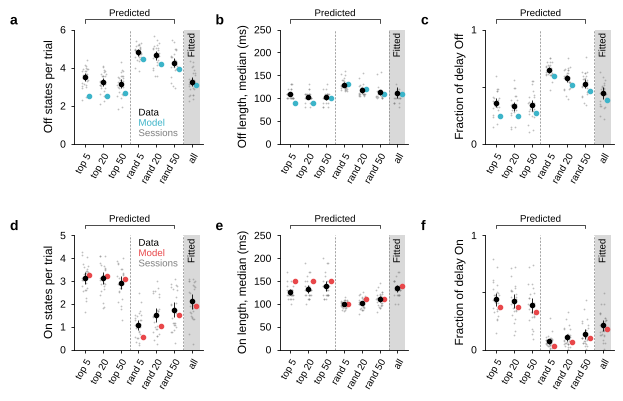

In [6]:
fig = fig2.draw(ses, model)
style.save(fig, '../figures/fig2.png')

## 3. Check the data pipeline on one session (optional, a few minutes)
Decodes one session with all units and compares its statistics with the stored table.

In [7]:
RUN, SESSION = False, '211011'                 # the smallest session
if RUN:
    S = recordings.Session(os.path.join(paths.DATA, f'{SESSION}.mat'))
    key = ('all', S.n_units, 0)
    conf = S.confidence(S.sets[key])
    z, states = S.states(conf)
    row, _ = S.readout_row(key, conf, z, states)
    stored = pd.read_csv(paths.results('recordings', 'readout_per_session.csv'))
    print(pd.DataFrame([row, stored[(stored.session == int(SESSION)) & (stored.set == 'all')].iloc[0].to_dict()],
                       index=['recomputed', 'stored'])[['off_per_trial', 'frac_off', 'on_per_trial', 'frac_on', 'mu_on']])